In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import(RocCurveDisplay, accuracy_score, confusion_matrix, recall_score, roc_auc_score, roc_curve)

In [3]:
data = pd.read_csv("data/nacimientos_simplificado.csv")

data.head()

,BAJO_PESO,EDAD_MADRE,CONSULTAS,GEMELAR,REGIMEN
0,0,23,5,0,Contributivo
1,0,38,12,0,Contributivo
2,0,31,9,0,Contributivo
3,0,22,9,0,Contributivo
4,0,34,4,0,Contributivo


In [4]:
entrenamiento = data.iloc[:1400]
test = data.iloc[1400:]

In [6]:
modelo = smf.glm("BAJO_PESO~EDAD_MADRE+CONSULTAS+GEMELAR+REGIMEN", data = entrenamiento, family = sm.families.Binomial()).fit()


In [7]:
modelo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:              BAJO_PESO   No. Observations:                 1400
Model:                            GLM   Df Residuals:                     1394
Model Family:                Binomial   Df Model:                            5
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -441.20
Date:                Fri, 23 Oct 2026   Deviance:                       882.40
Time:                        17:40:49   Pearson chi2:                 1.40e+03
No. Iterations:                     5   Pseudo R-squ. (CS):            0.06915
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -1.4400      0.485     -2.966      0.003      -2.392      -0.488
REGIMEN[T.NoAsegurado]    -0.0283      0.318     -0.089      0.929      -0.652       0.596
REGIMEN[T.Subsidiado]      0.1764      0.209      0.843      0.399      -0.234       0.587
EDAD_MADRE                 0.0113      0.015      0.745      0.456      -0.018       0.041
CONSULTAS                 -0.1545      0.036     -4.248      0.000      -0.226      -0.083
GEMELAR                    4.0486      0.534      7.585      0.000       3.003       5.095
==========================================================================================
"""

In [8]:
np.exp(modelo.params)

Intercept                  0.236930
REGIMEN[T.NoAsegurado]     0.972094
REGIMEN[T.Subsidiado]      1.192962
EDAD_MADRE                 1.011314
CONSULTAS                  0.856829
GEMELAR                   57.318988
dtype: float64

In [9]:
nueva = pd.DataFrame({"EDAD_MADRE": [30], "CONSULTAS": [4], "GEMELAR": [0], "REGIMEN":["Subsidiado"]})

modelo.predict(nueva)

0    0.175941
dtype: float64

In [13]:
y_prueba = test["BAJO_PESO"]
prob_test = modelo.predict(test)

print(pd.crosstab(y_prueba, prob_test>=0.5))


col_0      False  True 
BAJO_PESO              
0            538      2
1             53      7


In [15]:
prediccion = prob_test >= 0.5

confusion_matrix(y_prueba, prediccion)

array([[538,   2],
       [ 53,   7]])

In [ ]:
print(roc_auc_score(y_prueba, prob_test))

0.7179475308641974


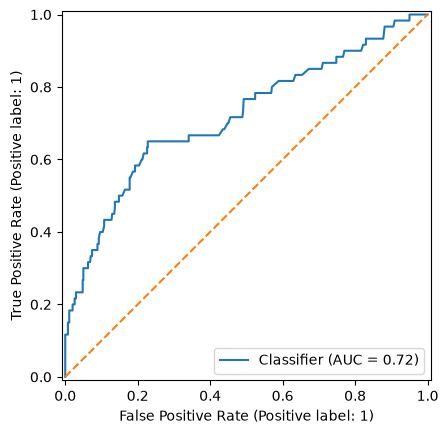

In [19]:
RocCurveDisplay.from_predictions(y_prueba, prob_test)
plt.plot([0,1], [0,1], linestyle = "--")

In [23]:
fpr, tpr, umbrales = roc_curve(entrenamiento["BAJO_PESO"], modelo.fittedvalues, drop_intermediate=False)

i = np.argmin((1-tpr)**2 + fpr**2)

corte_optimo = umbrales[i]

print(corte_optimo)

0.10430052955852814


In [27]:
lista = [corte_optimo, 0.25, 0.5]


for corte in lista:
    prediccion = prob_test>= corte
    print(confusion_matrix(y_prueba, prediccion))
    print("Sensibilidad:", recall_score(y_prueba, prediccion),
          "TCC:", accuracy_score(y_prueba, prediccion))

[[365 175]
 [ 21  39]]
Sensibilidad: 0.65 TCC: 0.6733333333333333
[[534   6]
 [ 50  10]]
Sensibilidad: 0.16666666666666666 TCC: 0.9066666666666666
[[538   2]
 [ 53   7]]
Sensibilidad: 0.11666666666666667 TCC: 0.9083333333333333
